<a href="https://colab.research.google.com/github/ishi-chat/global-quality-growth-portfolio/blob/main/fundamental_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. download python libraries

In [ ]:
python -m pip install yfinance pandas numpy openpyxl

2. Create folder paths on google drive

In [24]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/global-quality-growth-portfolio"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully.")

Project folders created successfully.


3. download stock price data

In [5]:
import yfinance as yf
import pandas as pd

tickers = [
    "MSFT",
    "ASML.AS",
    "REL.L",
    "6861.T",
    "CNR.TO"
]

prices = yf.download(
    tickers,
    start="2020-01-01",
    auto_adjust=True,
    progress=False
)["Close"]

print(prices.head())

Ticker            6861.T     ASML.AS      CNR.TO        MSFT        REL.L
Date                                                                     
2020-01-02           NaN  253.626343  103.932373  151.544296  1900.109863
2020-01-03           NaN  252.261230  103.260849  149.657288  1907.099121
2020-01-06  37434.484375  247.695190  102.824799  150.044128  1895.616699
2020-01-07  37770.699219  252.684875  102.842239  148.676041  1890.125122
2020-01-08  37530.550781  254.850204  104.228920  151.044220  1897.114136


4. Save prices to google drive files

In [6]:
prices.to_csv(
    RAW_DIR / "historical_prices_local.csv"
)

print("Historical prices saved successfully.")

Historical prices saved successfully.


5. Save co FS

In [7]:
for ticker in tickers:

    print(f"Downloading {ticker}")

    stock = yf.Ticker(ticker)

    income = stock.income_stmt
    balance = stock.balance_sheet
    cashflow = stock.cashflow

    name = ticker.replace(".", "_")

    income.to_csv(
        RAW_DIR / f"{name}_income.csv"
    )

    balance.to_csv(
        RAW_DIR / f"{name}_balance.csv"
    )

    cashflow.to_csv(
        RAW_DIR / f"{name}_cashflow.csv"
    )

print("All financial statements saved.")

All financial statements saved.


6. Save files

In [8]:
import os

files = os.listdir(RAW_DIR)

for file in sorted(files):
    print(file)

6861_T_balance.csv
6861_T_cashflow.csv
6861_T_income.csv
ASML_AS_balance.csv
ASML_AS_cashflow.csv
ASML_AS_income.csv
CNR_TO_balance.csv
CNR_TO_cashflow.csv
CNR_TO_income.csv
MSFT_balance.csv
MSFT_cashflow.csv
MSFT_income.csv
REL_L_balance.csv
REL_L_cashflow.csv
REL_L_income.csv
historical_prices_local.csv


7. Create one database

In [9]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

income = pd.read_csv(
    RAW_DIR / "MSFT_income.csv",
    index_col=0
)

balance = pd.read_csv(
    RAW_DIR / "MSFT_balance.csv",
    index_col=0
)

cashflow = pd.read_csv(
    RAW_DIR / "MSFT_cashflow.csv",
    index_col=0
)

print("Income statement:")
display(income.head(10))

print("Balance sheet:")
display(balance.head(10))

print("Cash flow statement:")
display(cashflow.head(10))

Income statement:


,2026-06-30,2025-06-30,2024-06-30,2023-06-30
Tax Effect Of Unusual Items,1.110650e+09,-7.721784e+07,-1.000900e+08,-2.850000e+06
Tax Rate For Calcs,1.940000e-01,1.762960e-01,1.823130e-01,1.900000e-01
Normalized EBITDA,2.017940e+11,1.558830e+11,1.322290e+11,1.051550e+11
Total Unusual Items,5.725000e+09,-4.380000e+08,-5.490000e+08,-1.500000e+07
Total Unusual Items Excluding Goodwill,5.725000e+09,-4.380000e+08,-5.490000e+08,-1.500000e+07
Net Income From Continuing Operation Net Minority Interest,1.337490e+11,1.018320e+11,8.813600e+10,7.236100e+10
Reconciled Depreciation,3.853400e+10,2.943300e+10,2.095800e+10,1.386100e+10
Reconciled Cost Of Revenue,1.063740e+11,8.783100e+10,7.411400e+10,6.586300e+10
EBITDA,2.075190e+11,1.554450e+11,1.316800e+11,1.051400e+11
EBIT,1.689850e+11,1.260120e+11,1.107220e+11,9.127900e+10


Balance sheet:


,2026-06-30,2025-06-30,2024-06-30,2023-06-30,2022-06-30
Ordinary Shares Number,7.427000e+09,7.434159e+09,7.434139e+09,7.432000e+09,NaN
Share Issued,7.427000e+09,7.434159e+09,7.434139e+09,7.432000e+09,NaN
Net Debt,1.935900e+10,1.290900e+10,3.331500e+10,1.253300e+10,NaN
Total Debt,5.682600e+10,6.058800e+10,6.712700e+10,5.996500e+10,NaN
Tangible Book Value,3.041270e+11,2.013660e+11,1.216600e+11,1.289710e+11,NaN
Invested Capital,4.826810e+11,3.866300e+11,3.201070e+11,2.534600e+11,NaN
Working Capital,3.888500e+10,4.991300e+10,3.444800e+10,8.010800e+10,NaN
Net Tangible Assets,3.041270e+11,2.013660e+11,1.216600e+11,1.289710e+11,NaN
Capital Lease Obligations,1.653200e+10,1.743700e+10,1.549700e+10,1.272800e+10,NaN
Common Stock Equity,4.423870e+11,3.434790e+11,2.684770e+11,2.062230e+11,NaN


Cash flow statement:


,2026-06-30,2025-06-30,2024-06-30,2023-06-30,2022-06-30
Free Cash Flow,6.698700e+10,7.161100e+10,7.407100e+10,5.947500e+10,NaN
Repurchase Of Capital Stock,-2.227100e+10,-1.842000e+10,-1.725400e+10,-2.224500e+10,NaN
Repayment Of Debt,-3.000000e+09,-3.216000e+09,-2.907000e+10,-2.750000e+09,NaN
Issuance Of Debt,0.000000e+00,0.000000e+00,2.439500e+10,0.000000e+00,NaN
Issuance Of Capital Stock,2.009000e+09,2.056000e+09,2.002000e+09,1.866000e+09,NaN
Capital Expenditure,-1.159480e+11,-6.455100e+10,-4.447700e+10,-2.810700e+10,NaN
End Cash Position,2.093500e+10,3.024200e+10,1.831500e+10,3.470400e+10,NaN
Beginning Cash Position,3.024200e+10,1.831500e+10,3.470400e+10,1.393100e+10,NaN
Effect Of Exchange Rate Changes,-1.960000e+08,6.300000e+07,-2.100000e+08,-1.940000e+08,NaN
Changes In Cash,-9.111000e+09,1.186400e+10,-1.617900e+10,2.096700e+10,NaN


8. Read the 3 MSFT csv files and create a directory/variables

In [7]:
print("INCOME STATEMENT")
print(income.index.tolist())

print("\nBALANCE SHEET")
print(balance.index.tolist())

print("\nCASH FLOW STATEMENT")
print(cashflow.index.tolist())

INCOME STATEMENT
['Tax Effect Of Unusual Items', 'Tax Rate For Calcs', 'Normalized EBITDA', 'Total Unusual Items', 'Total Unusual Items Excluding Goodwill', 'Net Income From Continuing Operation Net Minority Interest', 'Reconciled Depreciation', 'Reconciled Cost Of Revenue', 'EBITDA', 'EBIT', 'Net Interest Income', 'Interest Expense', 'Interest Income', 'Normalized Income', 'Net Income From Continuing And Discontinued Operation', 'Total Expenses', 'Total Operating Income As Reported', 'Diluted Average Shares', 'Basic Average Shares', 'Diluted EPS', 'Basic EPS', 'Diluted NI Availto Com Stockholders', 'Net Income Common Stockholders', 'Net Income', 'Net Income Including Noncontrolling Interests', 'Net Income Continuous Operations', 'Tax Provision', 'Pretax Income', 'Other Income Expense', 'Other Non Operating Income Expenses', 'Special Income Charges', 'Write Off', 'Gain On Sale Of Security', 'Net Non Operating Interest Income Expense', 'Interest Expense Non Operating', 'Interest Income 

9. Extract financial data for all other companies, based MSFT keys and fuzzy matching others

In [17]:
def extract_metric(statement, possible_names):
    """
    Extract a financial metric from a statement.

    Returns missing values if the metric cannot
    be located.
    """

    for name in possible_names:
        if name in statement.index:
            return pd.to_numeric(
                statement.loc[name],
                errors="coerce"
            )

    return pd.Series(
        np.nan,
        index=statement.columns,
        dtype=float
    )


revenue = extract_metric(
    income,
    ["Total Revenue", "Operating Revenue"]
)

operating_income = extract_metric(
    income,
    ["Operating Income", "EBIT"]
)

net_income = extract_metric(
    income,
    ["Net Income", "Net Income Common Stockholders"]
)

operating_cf = extract_metric(
    cashflow,
    ["Operating Cash Flow", "Cash Flow From Continuing Operating Activities"]
)

capex = extract_metric(
    cashflow,
    ["Capital Expenditure", "Capital Expenditures"]
)

total_debt = extract_metric(
    balance,
    ["Total Debt"]
)

cash = extract_metric(
    balance,
    [
        "Cash And Cash Equivalents",
        "Cash Cash Equivalents And Short Term Investments"
    ]
)

10. Write this in a database

In [18]:
import pandas as pd

# Combine the extracted metrics into a single DataFrame for display
metrics_df = pd.DataFrame({
    "Revenue": revenue,
    "Operating Income": operating_income,
    "Net Income": net_income,
    "Operating Cash Flow": operating_cf,
    "Capital Expenditure": capex,
    "Total Debt": total_debt,
    "Cash & Equivalents": cash
})

print("--- Extracted MSFT Financial Metrics ---")
display(metrics_df)

--- Extracted MSFT Financial Metrics ---


,Revenue,Operating Income,Net Income,Operating Cash Flow,Capital Expenditure,Total Debt,Cash & Equivalents
2022-06-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-06-30,2.119150e+11,8.852300e+10,7.236100e+10,8.758200e+10,-2.810700e+10,5.996500e+10,3.470400e+10
2024-06-30,2.451220e+11,1.094330e+11,8.813600e+10,1.185480e+11,-4.447700e+10,6.712700e+10,1.831500e+10
2025-06-30,2.817240e+11,1.285280e+11,1.018320e+11,1.361620e+11,-6.455100e+10,6.058800e+10,3.024200e+10
2026-06-30,3.318390e+11,1.552370e+11,1.337490e+11,1.829350e+11,-1.159480e+11,5.682600e+10,2.093500e+10


11. Calculations (since capex is negative, we add)

In [19]:
fcf = operating_cf + capex
operating_margin = operating_income / revenue

fcf_margin = fcf / revenue
revenue.index = pd.to_datetime(revenue.index)

revenue = revenue.sort_index()

revenue_growth = revenue.pct_change(
    fill_method=None
)

print(revenue_growth)

2023-06-30         NaN
2024-06-30    0.156700
2025-06-30    0.149322
2026-06-30    0.177887
Name: Total Revenue, dtype: float64


12. Create a table, save as output

In [25]:
financials = pd.DataFrame({
    "Revenue": revenue,
    "Operating Income": operating_income,
    "Net Income": net_income,
    "Operating Cash Flow": operating_cf,
    "Capital Expenditure": capex,
    "Free Cash Flow": fcf,
    "Operating Margin": operating_margin,
    "FCF Margin": fcf_margin,
    "Revenue Growth": revenue_growth
})

financials.index.name = "Fiscal Year End"

financials = financials.sort_index()

display(financials)


financials.to_csv(
    PROCESSED_DIR / "MSFT_fundamentals.csv"
)

print("Microsoft fundamentals saved.")

,Revenue,Operating Income,Net Income,Operating Cash Flow,Capital Expenditure,Free Cash Flow,Operating Margin,FCF Margin,Revenue Growth
Fiscal Year End,,,,,,,,,
2022-06-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-06-30,2.119150e+11,8.852300e+10,7.236100e+10,8.758200e+10,-2.810700e+10,5.947500e+10,0.417729,0.280655,NaN
2024-06-30,2.451220e+11,1.094330e+11,8.813600e+10,1.185480e+11,-4.447700e+10,7.407100e+10,0.446443,0.302180,0.156700
2025-06-30,2.817240e+11,1.285280e+11,1.018320e+11,1.361620e+11,-6.455100e+10,7.161100e+10,0.456220,0.254188,0.149322
2026-06-30,3.318390e+11,1.552370e+11,1.337490e+11,1.829350e+11,-1.159480e+11,6.698700e+10,0.467808,0.201866,0.177887


Microsoft fundamentals saved.


13. Extend processing data for all 5 companies, all absolute values in reportring currency so far

In [26]:
tickers = [
    "MSFT",
    "ASML.AS",
    "REL.L",
    "6861.T",
    "CNR.TO"
]

In [27]:
import os
import pandas as pd
import numpy as np

# Loop through all tickers to automate the data pipeline
for ticker in tickers:
    print(f"Processing financials for {ticker}...")

    # Generate the normalized name used for the CSV file saving
    name = ticker.replace(".", "_")

    # File paths for raw statements
    income_path = RAW_DIR / f"{name}_income.csv"
    balance_path = RAW_DIR / f"{name}_balance.csv"
    cashflow_path = RAW_DIR / f"{name}_cashflow.csv"

    # Skip if file sets are missing
    if not (income_path.exists() and balance_path.exists() and cashflow_path.exists()):
        print(f"Skipping {ticker}: Missing raw CSV files.")
        continue

    # Load statements
    ticker_income = pd.read_csv(income_path, index_col=0)
    ticker_balance = pd.read_csv(balance_path, index_col=0)
    ticker_cashflow = pd.read_csv(cashflow_path, index_col=0)

    # Extract metrics using the predefined extract_metric helper function
    ticker_revenue = extract_metric(ticker_income, ["Total Revenue", "Operating Revenue"])
    ticker_operating_income = extract_metric(ticker_income, ["Operating Income", "EBIT"])
    ticker_net_income = extract_metric(ticker_income, ["Net Income", "Net Income Common Stockholders"])
    ticker_operating_cf = extract_metric(ticker_cashflow, ["Operating Cash Flow", "Cash Flow From Continuing Operating Activities"])
    ticker_capex = extract_metric(ticker_cashflow, ["Capital Expenditure", "Capital Expenditures"])
    ticker_total_debt = extract_metric(ticker_balance, ["Total Debt"])
    ticker_cash = extract_metric(ticker_balance, ["Cash And Cash Equivalents", "Cash Cash Equivalents And Short Term Investments"])

    # Apply Datetime indices to align correctly
    ticker_revenue.index = pd.to_datetime(ticker_revenue.index)
    ticker_operating_income.index = pd.to_datetime(ticker_operating_income.index)
    ticker_net_income.index = pd.to_datetime(ticker_net_income.index)
    ticker_operating_cf.index = pd.to_datetime(ticker_operating_cf.index)
    ticker_capex.index = pd.to_datetime(ticker_capex.index)
    ticker_total_debt.index = pd.to_datetime(ticker_total_debt.index)
    ticker_cash.index = pd.to_datetime(ticker_cash.index)

    # Calculations
    ticker_fcf = ticker_operating_cf + ticker_capex
    ticker_operating_margin = ticker_operating_income / ticker_revenue
    ticker_fcf_margin = ticker_fcf / ticker_revenue

    ticker_revenue_sorted = ticker_revenue.sort_index()
    ticker_revenue_growth = ticker_revenue_sorted.pct_change(fill_method=None)
    ticker_revenue_growth.index = pd.to_datetime(ticker_revenue_growth.index)

    # Compile into DataFrame
    ticker_financials = pd.DataFrame({
        "Revenue": ticker_revenue,
        "Operating Income": ticker_operating_income,
        "Net Income": ticker_net_income,
        "Operating Cash Flow": ticker_operating_cf,
        "Capital Expenditure": ticker_capex,
        "Free Cash Flow": ticker_fcf,
        "Operating Margin": ticker_operating_margin,
        "FCF Margin": ticker_fcf_margin,
        "Revenue Growth": ticker_revenue_growth,
        "Total Debt": ticker_total_debt,
        "Cash & Equivalents": ticker_cash
    })

    ticker_financials.index.name = "Fiscal Year End"
    ticker_financials = ticker_financials.sort_index()

    # Save to processed folder
    output_file = PROCESSED_DIR / f"{name}_fundamentals.csv"
    ticker_financials.to_csv(output_file)
    print(f"Saved {ticker} processed fundamentals to {output_file.name}\n")

Processing financials for MSFT...
Saved MSFT processed fundamentals to MSFT_fundamentals.csv

Processing financials for ASML.AS...
Saved ASML.AS processed fundamentals to ASML_AS_fundamentals.csv

Processing financials for REL.L...
Saved REL.L processed fundamentals to REL_L_fundamentals.csv

Processing financials for 6861.T...
Saved 6861.T processed fundamentals to 6861_T_fundamentals.csv

Processing financials for CNR.TO...
Saved CNR.TO processed fundamentals to CNR_TO_fundamentals.csv



13. Combine all datasets and calculate 3 year CAGR

In [30]:
import pandas as pd
import numpy as np

# 1. Load and combine the individual processed files from PROCESSED_DIR
all_dfs = []
for ticker in tickers:
    name = ticker.replace(".", "_")
    file_path = PROCESSED_DIR / f"{name}_fundamentals.csv"
    if file_path.exists():
        df = pd.read_csv(file_path)
        df["Ticker"] = ticker
        all_dfs.append(df)

combined = pd.concat(all_dfs, ignore_index=True)
combined["Fiscal Year End"] = pd.to_datetime(combined["Fiscal Year End"])

# 2. Sort the combined DataFrame
combined = combined.sort_values(
    ["Ticker", "Fiscal Year End"]
)

# 3. Calculate the 3-year Revenue CAGR
def calculate_cagr(group):
    group = group.sort_values("Fiscal Year End").copy()

    previous_revenue = group["Revenue"].shift(3)
    previous_date = group["Fiscal Year End"].shift(3)

    years = (
        group["Fiscal Year End"] - previous_date
    ).dt.days / 365.25

    valid = (
        (group["Revenue"] > 0) &
        (previous_revenue > 0) &
        years.between(2.7, 3.3)
    )

    group["Revenue CAGR 3Y"] = np.where(
        valid,
        (
            group["Revenue"] / previous_revenue
        ) ** (1 / years) - 1,
        np.nan
    )

    return group

combined = pd.concat(
    [
        calculate_cagr(group)
        for _, group in combined.groupby("Ticker")
    ],
    ignore_index=True
)

display(combined.head())

,Fiscal Year End,Revenue,Operating Income,Net Income,Operating Cash Flow,Capital Expenditure,Free Cash Flow,Operating Margin,FCF Margin,Revenue Growth,Total Debt,Cash & Equivalents,Ticker,Revenue CAGR 3Y
0,2022-03-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6861.T,NaN
1,2023-03-31,9.224220e+11,4.989150e+11,3.629630e+11,3.026280e+11,-3.934500e+10,2.632830e+11,0.540875,0.285426,NaN,NaN,4.336560e+11,6861.T,NaN
2,2024-03-31,9.672880e+11,4.950140e+11,3.696420e+11,3.879160e+11,-1.249200e+10,3.754240e+11,0.511755,0.388120,0.048639,NaN,5.203560e+11,6861.T,NaN
3,2025-03-31,1.059145e+12,5.497750e+11,3.986560e+11,4.095220e+11,-1.434200e+10,3.951800e+11,0.519074,0.373112,0.094963,NaN,5.790510e+11,6861.T,NaN
4,2026-03-31,1.169289e+12,5.957590e+11,4.451850e+11,4.306800e+11,-2.837100e+10,4.023090e+11,0.509505,0.344063,0.103993,NaN,5.969760e+11,6861.T,0.082238


In [32]:
def calculate_fundamentals(ticker):

    income, balance, cashflow = load_financials(ticker)

    revenue = get_metric(
        income,
        ["Total Revenue", "Operating Revenue"]
    )

    ebit = get_metric(
        income,
        ["Operating Income", "EBIT"]
    )

    net_income = get_metric(
        income,
        ["Net Income", "Net Income Common Stockholders"]
    )

    pretax_income = get_metric(
        income,
        ["Pretax Income"]
    )

    tax_provision = get_metric(
        income,
        ["Tax Provision"]
    )

    operating_cf = get_metric(
        cashflow,
        ["Operating Cash Flow"]
    )

    capex = get_metric(
        cashflow,
        ["Capital Expenditure"]
    )

    total_debt = get_metric(
        balance,
        ["Total Debt"]
    )

    cash = get_metric(
        balance,
        [
            "Cash And Cash Equivalents",
            "Cash Cash Equivalents And Short Term Investments"
        ]
    )

    equity = get_metric(
        balance,
        ["Stockholders Equity", "Total Equity Gross Minority Interest"]
    )

    # Create a date-aligned table
    df = pd.DataFrame({
        "Revenue": revenue,
        "EBIT": ebit,
        "Net Income": net_income,
        "Pretax Income": pretax_income,
        "Tax Provision": tax_provision,
        "Operating CF": operating_cf,
        "CapEx": capex,
        "Total Debt": total_debt,
        "Cash": cash,
        "Equity": equity
    })

    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    # Only use fiscal years supported by the income statement
    df = df.loc[revenue.index].sort_index()

    # Check fiscal years
    year_gap = df.index.to_series().diff().dt.days

    annual_gap = year_gap.between(330, 400)

    # Free cash flow:
    # Yahoo commonly represents CapEx as a negative cash flow.
    # Treat positive CapEx as an outflow, too.
    df["FCF"] = df["Operating CF"] - df["CapEx"].abs()

    # Profitability
    df["Operating Margin"] = df["EBIT"] / df["Revenue"]

    df["FCF Margin"] = df["FCF"] / df["Revenue"]

    # Annual revenue growth
    df["Revenue Growth"] = (
        df["Revenue"].pct_change(fill_method=None)
        .where(annual_gap)
    )

    # Effective tax rate
    tax_rate = (
        df["Tax Provision"] / df["Pretax Income"]
    )

    # Use only plausible rates; flag exceptions for review
    tax_rate = tax_rate.where(
        tax_rate.between(0, 1)
    )

    df["Effective Tax Rate"] = tax_rate

    # Net operating profit after tax
    df["NOPAT"] = df["EBIT"] * (1 - tax_rate)

    # Simplified invested capital
    df["Invested Capital"] = (
        df["Total Debt"] + df["Equity"] - df["Cash"]
    )

    # Use average invested capital
    average_ic = (
        df["Invested Capital"] +
        df["Invested Capital"].shift(1)
    ) / 2

    # Avoid inappropriate calculations where dates are not annual
    average_ic = average_ic.where(annual_gap)

    # Return on invested capital
    df["ROIC"] = (
        df["NOPAT"] / average_ic
    ).where(average_ic > 0)

    # Return on equity
    average_equity = (
        df["Equity"] + df["Equity"].shift(1)
    ) / 2

    average_equity = average_equity.where(annual_gap)

    df["ROE"] = (
        df["Net Income"] / average_equity
    ).where(average_equity > 0)

    # Net debt
    df["Net Debt"] = df["Total Debt"] - df["Cash"]

    df["Ticker"] = ticker

    return df

14. Creating a company comparison table

In [36]:
import numpy as np

# Dynamically calculate Net Debt if the individual components exist but Net Debt is missing
if "Net Debt" not in combined.columns:
    total_debt = combined.get("Total Debt", 0).fillna(0)
    cash = combined.get("Cash & Equivalents", 0).fillna(0)
    combined["Net Debt"] = total_debt - cash

latest = (
    combined
    .sort_values("Fiscal Year End")
    .groupby("Ticker")
    .tail(1)
    .copy()
)

metrics = [
    "Ticker",
    "Fiscal Year End",
    "ROIC",
    "ROE",
    "Revenue CAGR 3Y",
    "Operating Margin",
    "FCF Margin",
    "Net Debt"
]

# Dynamically add missing metrics as NaN to prevent KeyError
for metric in metrics:
    if metric not in latest.columns:
        latest[metric] = np.nan

comparison = latest[metrics]

display(
    comparison.style.format({
        "ROIC": "{:.2%}",
        "ROE": "{:.2%}",
        "Revenue CAGR 3Y": "{:.2%}",
        "Operating Margin": "{:.2%}",
        "FCF Margin": "{:.2%}",
        "Net Debt": "{:,.0f}"
    }, na_rep="N/A")
)

,Ticker,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt
14,CNR.TO,2025-12-31 00:00:00,N/A,N/A,0.38%,38.07%,19.60%,"21,280,000,000"
9,ASML.AS,2025-12-31 00:00:00,N/A,N/A,15.55%,34.60%,33.76%,"-8,525,100,000"
24,REL.L,2025-12-31 00:00:00,N/A,N/A,3.89%,31.11%,24.10%,"7,136,000,000"
4,6861.T,2026-03-31 00:00:00,N/A,N/A,8.22%,50.95%,34.41%,"-596,976,000,000"
19,MSFT,2026-06-30 00:00:00,N/A,N/A,16.12%,46.78%,20.19%,"35,891,000,000"


In [38]:
# Let's verify if all 5 tickers are in the consolidated 'combined' DataFrame and inspect its shape.
print("Tickers present in the unified dataset:", combined["Ticker"].unique())
print(f"Dataset shape: {combined.shape[0]} rows and {combined.shape[1]} columns.")
print("\nFirst 5 rows of the consolidated dataset:")
display(combined.head())


Tickers present in the unified dataset: ['6861.T' 'ASML.AS' 'CNR.TO' 'MSFT' 'REL.L']
Dataset shape: 25 rows and 15 columns.

First 5 rows of the consolidated dataset:


,Fiscal Year End,Revenue,Operating Income,Net Income,Operating Cash Flow,Capital Expenditure,Free Cash Flow,Operating Margin,FCF Margin,Revenue Growth,Total Debt,Cash & Equivalents,Ticker,Revenue CAGR 3Y,Net Debt
0,2022-03-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6861.T,NaN,0.000000e+00
1,2023-03-31,9.224220e+11,4.989150e+11,3.629630e+11,3.026280e+11,-3.934500e+10,2.632830e+11,0.540875,0.285426,NaN,NaN,4.336560e+11,6861.T,NaN,-4.336560e+11
2,2024-03-31,9.672880e+11,4.950140e+11,3.696420e+11,3.879160e+11,-1.249200e+10,3.754240e+11,0.511755,0.388120,0.048639,NaN,5.203560e+11,6861.T,NaN,-5.203560e+11
3,2025-03-31,1.059145e+12,5.497750e+11,3.986560e+11,4.095220e+11,-1.434200e+10,3.951800e+11,0.519074,0.373112,0.094963,NaN,5.790510e+11,6861.T,NaN,-5.790510e+11
4,2026-03-31,1.169289e+12,5.957590e+11,4.451850e+11,4.306800e+11,-2.837100e+10,4.023090e+11,0.509505,0.344063,0.103993,NaN,5.969760e+11,6861.T,0.082238,-5.969760e+11


In [40]:
# Save the unified dataset to the processed folder as 'global_fundamentals.csv'
global_output_path = PROCESSED_DIR / "global_fundamentals.csv"
combined.to_csv(global_output_path, index=False)

print(f"Unified dataset successfully saved to: {global_output_path}")

Unified dataset successfully saved to: /content/drive/MyDrive/global-quality-growth-portfolio/data/processed/global_fundamentals.csv


In [41]:
import pandas as pd
import numpy as np

# Predefined helper to match metrics
def get_metric(df, possible_names):
    for name in possible_names:
        if name in df.index:
            return pd.to_numeric(df.loc[name], errors='coerce')
    return pd.Series(np.nan, index=df.columns, dtype=float)

# Loop through each ticker to compute full metrics using your formula logic
for ticker in tickers:
    print(f"Recalculating full metrics for {ticker}...")
    name = ticker.replace(".", "_")

    # Load raw statements
    income_path = RAW_DIR / f"{name}_income.csv"
    balance_path = RAW_DIR / f"{name}_balance.csv"
    cashflow_path = RAW_DIR / f"{name}_cashflow.csv"

    if not (income_path.exists() and balance_path.exists() and cashflow_path.exists()):
        print(f"Skipping {ticker}: Missing files.")
        continue

    income_df = pd.read_csv(income_path, index_col=0)
    balance_df = pd.read_csv(balance_path, index_col=0)
    cashflow_df = pd.read_csv(cashflow_path, index_col=0)

    # Basic Extracted Metrics
    revenue = get_metric(income_df, ["Total Revenue", "Operating Revenue"])
    ebit = get_metric(income_df, ["Operating Income", "EBIT"])
    net_income = get_metric(income_df, ["Net Income", "Net Income Common Stockholders"])
    pretax_income = get_metric(income_df, ["Pretax Income"])
    tax_provision = get_metric(income_df, ["Tax Provision"])
    operating_cf = get_metric(cashflow_df, ["Operating Cash Flow", "Cash Flow From Continuing Operating Activities"])
    capex = get_metric(cashflow_df, ["Capital Expenditure", "Capital Expenditures"])
    total_debt = get_metric(balance_df, ["Total Debt"])
    cash_eq = get_metric(balance_df, ["Cash And Cash Equivalents", "Cash Cash Equivalents And Short Term Investments"])
    equity = get_metric(balance_df, ["Stockholders Equity", "Total Equity Gross Minority Interest"])

    # Initialize local dataframe for alignment
    df = pd.DataFrame({
        "Revenue": revenue,
        "Operating Income": ebit,  # mapped to EBIT
        "Net Income": net_income,
        "Pretax Income": pretax_income,
        "Tax Provision": tax_provision,
        "Operating Cash Flow": operating_cf,
        "Capital Expenditure": capex,
        "Total Debt": total_debt,
        "Cash & Equivalents": cash_eq,
        "Equity": equity
    })

    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    # Only keep years present on the income statement (aligned with revenue)
    revenue_idx = pd.to_datetime(revenue.index)
    df = df.loc[df.index.isin(revenue_idx)].sort_index()

    # Check fiscal years and calculate annual gap
    year_gap = df.index.to_series().diff().dt.days
    annual_gap = year_gap.between(330, 400)

    # Calculations
    df["Free Cash Flow"] = df["Operating Cash Flow"] - df["Capital Expenditure"].abs()
    df["Operating Margin"] = df["Operating Income"] / df["Revenue"]
    df["FCF Margin"] = df["Free Cash Flow"] / df["Revenue"]
    df["Revenue Growth"] = df["Revenue"].pct_change(fill_method=None).where(annual_gap)

    # Effective tax rate (limited to between 0 and 1)
    tax_rate = df["Tax Provision"] / df["Pretax Income"]
    tax_rate = tax_rate.where(tax_rate.between(0, 1))
    df["Effective Tax Rate"] = tax_rate

    # NOPAT
    df["NOPAT"] = df["Operating Income"] * (1 - tax_rate.fillna(0))

    # Invested Capital
    df["Invested Capital"] = df["Total Debt"].fillna(0) + df["Equity"].fillna(0) - df["Cash & Equivalents"].fillna(0)

    # ROIC with average invested capital
    average_ic = (df["Invested Capital"] + df["Invested Capital"].shift(1)) / 2
    average_ic = average_ic.where(annual_gap)
    df["ROIC"] = (df["NOPAT"] / average_ic).where(average_ic > 0)

    # ROE with average equity
    average_equity = (df["Equity"] + df["Equity"].shift(1)) / 2
    average_equity = average_equity.where(annual_gap)
    df["ROE"] = (df["Net Income"] / average_equity).where(average_equity > 0)

    # Net Debt
    df["Net Debt"] = df["Total Debt"].fillna(0) - df["Cash & Equivalents"].fillna(0)

    # Ensure output is cleaned up and saved
    df.index.name = "Fiscal Year End"
    df.to_csv(PROCESSED_DIR / f"{name}_fundamentals.csv")
    print(f"Saved complete metrics for {ticker}.")


Recalculating full metrics for MSFT...
Saved complete metrics for MSFT.
Recalculating full metrics for ASML.AS...
Saved complete metrics for ASML.AS.
Recalculating full metrics for REL.L...
Saved complete metrics for REL.L.
Recalculating full metrics for 6861.T...
Saved complete metrics for 6861.T.
Recalculating full metrics for CNR.TO...
Saved complete metrics for CNR.TO.


In [42]:
# Re-combine all files and apply 3-year Revenue CAGR calculation
all_dfs = []
for ticker in tickers:
    name = ticker.replace(".", "_")
    file_path = PROCESSED_DIR / f"{name}_fundamentals.csv"
    if file_path.exists():
        df = pd.read_csv(file_path)
        df["Ticker"] = ticker
        all_dfs.append(df)

combined = pd.concat(all_dfs, ignore_index=True)
combined["Fiscal Year End"] = pd.to_datetime(combined["Fiscal Year End"])
combined = combined.sort_values(["Ticker", "Fiscal Year End"])

# Re-apply CAGR
combined = pd.concat(
    [
        calculate_cagr(group)
        for _, group in combined.groupby("Ticker")
    ],
    ignore_index=True
)

# Save updated consolidated dataset
combined.to_csv(PROCESSED_DIR / "global_fundamentals.csv", index=False)
print("Fully updated global_fundamentals.csv has been saved!")
display(combined.head())


Fully updated global_fundamentals.csv has been saved!


,Fiscal Year End,Revenue,Operating Income,Net Income,Pretax Income,Tax Provision,Operating Cash Flow,Capital Expenditure,Total Debt,Cash & Equivalents,...,FCF Margin,Revenue Growth,Effective Tax Rate,NOPAT,Invested Capital,ROIC,ROE,Net Debt,Ticker,Revenue CAGR 3Y
0,2023-03-31,9.224220e+11,4.989150e+11,3.629630e+11,5.128300e+11,1.498660e+11,3.026280e+11,-3.934500e+10,NaN,4.336560e+11,...,0.285426,NaN,0.292233,3.531154e+11,2.057977e+12,NaN,NaN,-4.336560e+11,6861.T,NaN
1,2024-03-31,9.672880e+11,4.950140e+11,3.696420e+11,5.192950e+11,1.496530e+11,3.879160e+11,-1.249200e+10,NaN,5.203560e+11,...,0.388120,0.048639,0.288185,3.523584e+11,2.285837e+12,0.162235,0.139545,-5.203560e+11,6861.T,NaN
2,2025-03-31,1.059145e+12,5.497750e+11,3.986560e+11,5.610100e+11,1.623530e+11,4.095220e+11,-1.434200e+10,NaN,5.790510e+11,...,0.373112,0.094963,0.289394,3.906733e+11,2.529501e+12,0.162262,0.134801,-5.790510e+11,6861.T,NaN
3,2026-03-31,1.169289e+12,5.957590e+11,4.451850e+11,6.357560e+11,1.905700e+11,4.306800e+11,-2.837100e+10,NaN,5.969760e+11,...,0.344063,0.103993,0.299753,4.171782e+11,2.874495e+12,0.154396,0.135314,-5.969760e+11,6861.T,0.082238
4,2021-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN,0.000000e+00,ASML.AS,NaN


In [43]:
latest_actuals = (
    combined
    .sort_values("Fiscal Year End")
    .groupby("Ticker")
    .tail(1)
    .copy()
)

metrics_list = [
    "Ticker",
    "Fiscal Year End",
    "ROIC",
    "ROE",
    "Revenue CAGR 3Y",
    "Operating Margin",
    "FCF Margin",
    "Net Debt"
]

comparison_actuals = latest_actuals[metrics_list]

display(
    comparison_actuals.style.format({
        "ROIC": "{:.2%}",
        "ROE": "{:.2%}",
        "Revenue CAGR 3Y": "{:.2%}",
        "Operating Margin": "{:.2%}",
        "FCF Margin": "{:.2%}",
        "Net Debt": "{:,.0f}"
    }, na_rep="N/A")
)

,Ticker,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt
13,CNR.TO,2025-12-31 00:00:00,11.69%,22.15%,0.38%,38.07%,19.60%,"21,280,000,000"
8,ASML.AS,2025-12-31 00:00:00,86.51%,50.46%,15.55%,34.60%,33.76%,"-8,525,100,000"
22,REL.L,2025-12-31 00:00:00,23.23%,70.63%,3.89%,31.11%,24.10%,"7,136,000,000"
3,6861.T,2026-03-31 00:00:00,15.44%,13.53%,8.22%,50.95%,34.41%,"-596,976,000,000"
17,MSFT,2026-06-30 00:00:00,29.37%,34.04%,16.12%,46.78%,20.19%,"35,891,000,000"


In [44]:
# Fetch the newly calculated actual metrics from our freshly saved 'combined' dataset
latest_actuals = (
    combined
    .sort_values("Fiscal Year End")
    .groupby("Ticker")
    .tail(1)
    .copy()
)

metrics_list = [
    "Ticker",
    "Fiscal Year End",
    "ROIC",
    "ROE",
    "Revenue CAGR 3Y",
    "Operating Margin",
    "FCF Margin",
    "Net Debt"
]

comparison_actuals = latest_actuals[metrics_list]

display(
    comparison_actuals.style.format({
        "ROIC": "{:.2%}",
        "ROE": "{:.2%}",
        "Revenue CAGR 3Y": "{:.2%}",
        "Operating Margin": "{:.2%}",
        "FCF Margin": "{:.2%}",
        "Net Debt": "{:,.0f}"
    }, na_rep="N/A")
)

,Ticker,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt
13,CNR.TO,2025-12-31 00:00:00,11.69%,22.15%,0.38%,38.07%,19.60%,"21,280,000,000"
8,ASML.AS,2025-12-31 00:00:00,86.51%,50.46%,15.55%,34.60%,33.76%,"-8,525,100,000"
22,REL.L,2025-12-31 00:00:00,23.23%,70.63%,3.89%,31.11%,24.10%,"7,136,000,000"
3,6861.T,2026-03-31 00:00:00,15.44%,13.53%,8.22%,50.95%,34.41%,"-596,976,000,000"
17,MSFT,2026-06-30 00:00:00,29.37%,34.04%,16.12%,46.78%,20.19%,"35,891,000,000"


Create table with only latest figures (not time series)

In [45]:
latest = (
    combined
    .sort_values("Fiscal Year End")
    .groupby("Ticker")
    .tail(1)
    .copy()
)

metrics = [
    "Ticker",
    "Fiscal Year End",
    "ROIC",
    "ROE",
    "Revenue CAGR 3Y",
    "Operating Margin",
    "FCF Margin",
    "Net Debt"
]

comparison = latest[metrics]

display(
    comparison.style.format({
        "ROIC": "{:.2%}",
        "ROE": "{:.2%}",
        "Revenue CAGR 3Y": "{:.2%}",
        "Operating Margin": "{:.2%}",
        "FCF Margin": "{:.2%}",
        "Net Debt": "{:,.0f}"
    }, na_rep="N/A")
)

,Ticker,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt
13,CNR.TO,2025-12-31 00:00:00,11.69%,22.15%,0.38%,38.07%,19.60%,"21,280,000,000"
8,ASML.AS,2025-12-31 00:00:00,86.51%,50.46%,15.55%,34.60%,33.76%,"-8,525,100,000"
22,REL.L,2025-12-31 00:00:00,23.23%,70.63%,3.89%,31.11%,24.10%,"7,136,000,000"
3,6861.T,2026-03-31 00:00:00,15.44%,13.53%,8.22%,50.95%,34.41%,"-596,976,000,000"
17,MSFT,2026-06-30 00:00:00,29.37%,34.04%,16.12%,46.78%,20.19%,"35,891,000,000"


In [46]:
comparison.to_csv(
    PROCESSED_DIR / "company_quality_metrics.csv",
    index=False
)

print("Company comparison saved.")

Company comparison saved.


Qualit checks on data:

In [48]:
quality_check = (
    comparison
    .set_index("Ticker")
    .isna()
)

print("Missing metrics by company:")

display(quality_check)

print("Companies with ROIC above 100%:")

display(
    comparison[comparison["ROIC"] > 1]
)

print("Companies with negative FCF margins:")

display(
    comparison[comparison["FCF Margin"] < 0]
)

Missing metrics by company:


,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt
Ticker,,,,,,,
CNR.TO,False,False,False,False,False,False,False
ASML.AS,False,False,False,False,False,False,False
REL.L,False,False,False,False,False,False,False
6861.T,False,False,False,False,False,False,False
MSFT,False,False,False,False,False,False,False


Companies with ROIC above 100%:


,Ticker,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt


Companies with negative FCF margins:


,Ticker,Fiscal Year End,ROIC,ROE,Revenue CAGR 3Y,Operating Margin,FCF Margin,Net Debt


Consolidated code for building a Quality-Growth Scoring Model that ranks your five companies based on profitability, growth, cash generation, financial strength and, when available, valuation.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Financial data loaded successfully.

Dataset dimensions:
(23, 23)

Available columns:
['Fiscal Year End', 'Revenue', 'Operating Income', 'Net Income', 'Pretax Income', 'Tax Provision', 'Operating Cash Flow', 'Capital Expenditure', 'Total Debt', 'Cash & Equivalents', 'Equity', 'Free Cash Flow', 'Operating Margin', 'FCF Margin', 'Revenue Growth', 'Effective Tax Rate', 'NOPAT', 'Invested Capital', 'ROIC', 'ROE', 'Net Debt', 'Ticker', 'Revenue CAGR 3Y']


,Fiscal Year End,Revenue,Operating Income,Net Income,Pretax Income,Tax Provision,Operating Cash Flow,Capital Expenditure,Total Debt,Cash & Equivalents,...,FCF Margin,Revenue Growth,Effective Tax Rate,NOPAT,Invested Capital,ROIC,ROE,Net Debt,Ticker,Revenue CAGR 3Y
0,2023-03-31,9.224220e+11,4.989150e+11,3.629630e+11,5.128300e+11,1.498660e+11,3.026280e+11,-3.934500e+10,NaN,4.336560e+11,...,0.285426,NaN,0.292233,3.531154e+11,2.057977e+12,NaN,NaN,-4.336560e+11,6861.T,NaN
1,2024-03-31,9.672880e+11,4.950140e+11,3.696420e+11,5.192950e+11,1.496530e+11,3.879160e+11,-1.249200e+10,NaN,5.203560e+11,...,0.388120,0.048639,0.288185,3.523584e+11,2.285837e+12,0.162235,0.139545,-5.203560e+11,6861.T,NaN
2,2025-03-31,1.059145e+12,5.497750e+11,3.986560e+11,5.610100e+11,1.623530e+11,4.095220e+11,-1.434200e+10,NaN,5.790510e+11,...,0.373112,0.094963,0.289394,3.906733e+11,2.529501e+12,0.162262,0.134801,-5.790510e+11,6861.T,NaN
3,2026-03-31,1.169289e+12,5.957590e+11,4.451850e+11,6.357560e+11,1.905700e+11,4.306800e+11,-2.837100e+10,NaN,5.969760e+11,...,0.344063,0.103993,0.299753,4.171782e+11,2.874495e+12,0.154396,0.135314,-5.969760e+11,6861.T,0.082238
4,2021-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN,0.000000e+00,ASML.AS,NaN



Latest financial observations:


,Ticker,Fiscal Year End,ROIC,Operating Margin,Revenue CAGR 3Y,FCF Margin
0,6861.T,2026-03-31,0.154396,0.509505,0.082238,0.344063
1,ASML.AS,2025-12-31,0.865092,0.345955,0.155473,0.337564
2,CNR.TO,2025-12-31,0.116949,0.380663,0.003823,0.195966
3,MSFT,2026-06-30,0.293689,0.467808,0.161200,0.201866
4,REL.L,2025-12-31,0.232282,0.311053,0.038874,0.240980



No valuation_inputs.csv found. Calculating provisional scores only.

GLOBAL QUALITY-GROWTH RANKINGS


,Rank,Ticker,Quality Score,Growth Score,Cash Flow Score,Financial Strength Score,Valuation Score,Quality-Growth Score / 75,Final Score / 100,Scoring Status
0,1.0,6861.T,70.0,60.0,100.0,100.0,NaN,59.5,NaN,Provisional - valuation missing
1,2.0,ASML.AS,70.0,80.0,80.0,80.0,NaN,57.5,NaN,Provisional - valuation missing
3,3.0,MSFT,80.0,100.0,40.0,60.0,NaN,54.0,NaN,Provisional - valuation missing
4,4.0,REL.L,40.0,40.0,60.0,40.0,NaN,34.0,NaN,Provisional - valuation missing
2,5.0,CNR.TO,40.0,20.0,20.0,20.0,NaN,20.0,NaN,Provisional - valuation missing


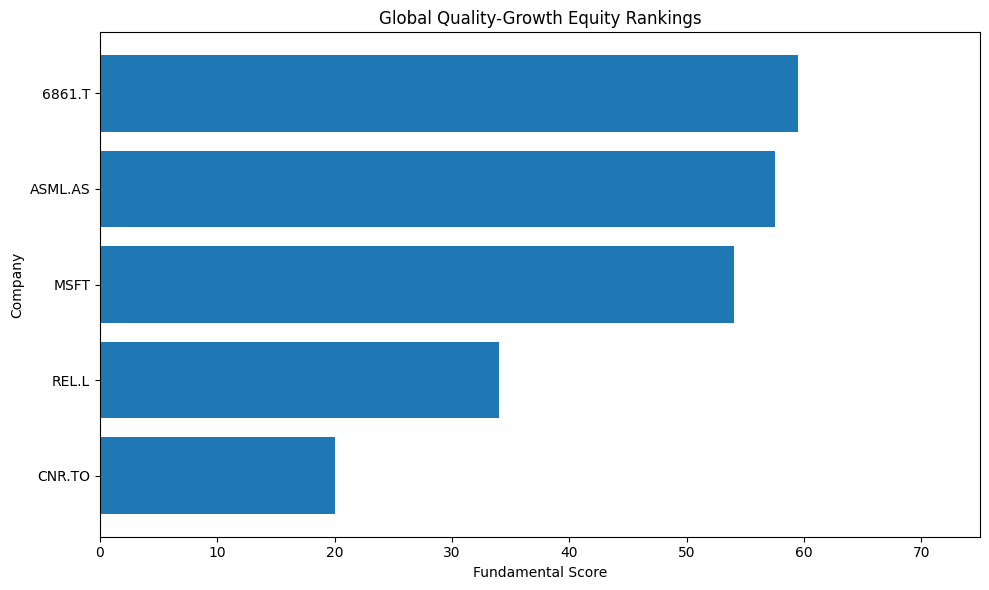


Files saved successfully.
/content/drive/MyDrive/global-quality-growth-portfolio/data/processed/company_quality_growth_scores.csv
/content/drive/MyDrive/global-quality-growth-portfolio/data/processed/quality_growth_rankings.csv

DATA QUALITY REPORT
Total companies: 5
Companies with complete financial scores: 5
Companies with complete five-category scores: 0

Missing observations by category:
Quality Score               0
Growth Score                0
Cash Flow Score             0
Financial Strength Score    0
Valuation Score             5
dtype: int64

IMPORTANT:
These scores are relative to a small, selected research universe.
They are not validated predictions of future stock returns.
Expand the universe and validate accounting definitions before drawing investment conclusions.


In [2]:
# ============================================================
# GLOBAL QUALITY-GROWTH EQUITY PORTFOLIO
# MODULE 4: FUNDAMENTAL SCORING MODEL
#
# Objective:
# Rank global equities using:
# 1. Quality
# 2. Growth
# 3. Cash Flow
# 4. Financial Strength
# 5. Valuation (when available)
#
# Output:
# company_quality_growth_scores.csv
# quality_growth_rankings.csv
#
# ============================================================


# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive


# ============================================================
# STEP 2: CONNECT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/global-quality-growth-portfolio"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# STEP 3: LOAD YOUR FUNDAMENTAL DATA
# ============================================================

file_path = PROCESSED_DIR / "global_fundamentals.csv"

df = pd.read_csv(file_path)

print("Financial data loaded successfully.")

print("\nDataset dimensions:")
print(df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())


# ============================================================
# STEP 4: PREPARE AND VALIDATE THE DATA
# ============================================================

# Convert fiscal dates
df["Fiscal Year End"] = pd.to_datetime(
    df["Fiscal Year End"],
    errors="coerce"
)

# Fix column mismatch: Map Operating Income to EBIT if EBIT is missing but Operating Income is present
if "EBIT" not in df.columns and "Operating Income" in df.columns:
    df["EBIT"] = df["Operating Income"]

# Check required columns
required_columns = [
    "Ticker",
    "Fiscal Year End",
    "ROIC",
    "Operating Margin",
    "FCF Margin",
    "Revenue CAGR 3Y",
    "Net Debt",
    "EBIT"
]

# The previous calculation produced Revenue CAGR 3Y.
# Ensure it was saved to global_fundamentals.csv.
# If not, calculate it below.

if "Revenue CAGR 3Y" not in df.columns:

    df = df.sort_values(
        ["Ticker", "Fiscal Year End"]
    ).copy()

    previous_revenue = df.groupby(
        "Ticker"
    )["Revenue"].shift(3)

    previous_date = df.groupby(
        "Ticker"
    )["Fiscal Year End"].shift(3)

    years = (
        df["Fiscal Year End"] - previous_date
    ).dt.days / 365.25

    valid = (
        (df["Revenue"] > 0) &
        (previous_revenue > 0) &
        years.between(2.7, 3.3)
    )

    df["Revenue CAGR 3Y"] = np.where(
        valid,
        (df["Revenue"] / previous_revenue)
        ** (1 / years) - 1,
        np.nan
    )

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert financial metrics to numeric values
numeric_columns = [
    "ROIC",
    "Operating Margin",
    "FCF Margin",
    "Revenue CAGR 3Y",
    "Net Debt",
    "EBIT"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Remove rows without valid dates
df = df.dropna(
    subset=["Ticker", "Fiscal Year End"]
)

# Keep the most recently reported annual observations
df = df.sort_values(
    ["Ticker", "Fiscal Year End"]
)

latest = (
    df.groupby("Ticker")
    .tail(1)
    .copy()
    .reset_index(drop=True)
)

print("\nLatest financial observations:")
display(
    latest[[
        "Ticker",
        "Fiscal Year End",
        "ROIC",
        "Operating Margin",
        "Revenue CAGR 3Y",
        "FCF Margin"
    ]]
)


# ============================================================
# STEP 5: CALCULATE FINANCIAL STRENGTH
# ============================================================

# Net Debt / EBIT is used as a preliminary leverage proxy.
#
# Lower leverage is preferred.
#
# IMPORTANT:
# Net Debt / EBIT is NOT Net Debt / EBITDA.
# We will replace this with more appropriate sector-specific
# leverage metrics as the research universe expands.
#
# Companies with zero or negative EBIT will not receive
# a leverage score from this measure.

latest["Net Debt / EBIT"] = np.where(
    latest["EBIT"] > 0,
    latest["Net Debt"] / latest["EBIT"],
    np.nan
)


# ============================================================
# STEP 6: DEFINE A NORMALISED SCORING FUNCTION
# ============================================================

# Percentile ranking converts different financial metrics
# into comparable scores between 0 and 100.
#
# Higher scores represent more attractive characteristics.
#
# For some metrics, higher is better:
# ROIC, Operating Margin, Growth, FCF Margin.
#
# For leverage, lower is better.
#
# Missing values remain missing.
#
# This is a relative ranking method.
# It does not establish that a company meets an
# absolute standard of financial quality.

def percentile_score(series, higher_is_better=True):

    values = pd.to_numeric(
        series,
        errors="coerce"
    )

    # Need at least two valid values to rank meaningfully
    if values.notna().sum() < 2:
        return pd.Series(
            np.nan,
            index=series.index
        )

    scores = values.rank(
        pct=True,
        ascending=higher_is_better
    ) * 100

    return scores


# ============================================================
# STEP 7: CALCULATE QUALITY SCORES
# ============================================================

# Quality: 25% of final composite score
#
# ROIC evaluates capital efficiency.
# Operating margin evaluates operating profitability.

latest["ROIC Score"] = percentile_score(
    latest["ROIC"]
)

latest["Operating Margin Score"] = percentile_score(
    latest["Operating Margin"]
)

# Average the available quality measures
latest["Quality Score"] = latest[
    ["ROIC Score", "Operating Margin Score"]
].mean(axis=1)


# ============================================================
# STEP 8: CALCULATE GROWTH SCORES
# ============================================================

# Growth: 20% of final composite score
#
# Begin with three-year revenue CAGR.
#
# Later we will add:
# - EPS CAGR
# - FCF CAGR
# - Reinvestment efficiency
# - Growth consistency

latest["Growth Score"] = percentile_score(
    latest["Revenue CAGR 3Y"]
)


# ============================================================
# STEP 9: CALCULATE CASH FLOW SCORES
# ============================================================

# Cash flow: 20% of final composite score
#
# FCF margin measures cash generation relative to sales.

latest["Cash Flow Score"] = percentile_score(
    latest["FCF Margin"]
)


# ============================================================
# STEP 10: CALCULATE FINANCIAL STRENGTH SCORES
# ============================================================

# Financial strength: 10% of composite score
#
# Lower Net Debt / EBIT receives a higher score.
#
# Negative net debt can represent a net cash position.
# Treat unusual leverage values as review items.

latest["Financial Strength Score"] = percentile_score(
    latest["Net Debt / EBIT"],
    higher_is_better=False
)


# ============================================================
# STEP 11: OPTIONAL VALUATION DATA
# ============================================================

# Valuation represents 25% of the final score.
#
# If valuation_inputs.csv exists, this code expects:
#
# Ticker
# FCF_Yield
# Forward_PE
#
# FCF_Yield should be a decimal:
# e.g., 0.05 represents 5%.
#
# If the file does not exist, valuation scores remain missing.
#
# We do NOT invent valuation figures.

valuation_file = (
    PROCESSED_DIR / "valuation_inputs.csv"
)

latest["Valuation Score"] = np.nan

if valuation_file.exists():

    valuations = pd.read_csv(valuation_file)

    required_valuation_columns = [
        "Ticker",
        "FCF_Yield",
        "Forward_PE"
    ]

    if not all(
         col in valuations.columns
         for col in required_valuation_columns
    ):
        raise ValueError(
            "Valuation file must contain "
            "Ticker, FCF_Yield and Forward_PE."
        )

    if valuations["Ticker"].duplicated().any():
        raise ValueError(
            "Duplicate tickers in valuation_inputs.csv"
        )

    valuations["FCF_Yield"] = pd.to_numeric(
        valuations["FCF_Yield"],
        errors="coerce"
    )

    valuations["Forward_PE"] = pd.to_numeric(
        valuations["Forward_PE"],
        errors="coerce"
    )

    latest = latest.merge(
        valuations[required_valuation_columns],
        on="Ticker",
        how="left"
    )

    # Forward P/E is meaningful for positive expected earnings
    latest.loc[
        latest["Forward_PE"] <= 0,
        "Forward_PE"
    ] = np.nan

    # Higher FCF yield is preferred
    latest["FCF Yield Score"] = percentile_score(
        latest["FCF_Yield"]
    )

    # Lower forward P/E is preferred
    latest["Forward PE Score"] = percentile_score(
        latest["Forward_PE"],
        higher_is_better=False
    )

    latest["Valuation Score"] = latest[
        ["FCF Yield Score", "Forward PE Score"]
    ].mean(axis=1)

    # If only one of the two valuation metrics is available,
    # flag it rather than treating it as a complete valuation.
    complete_valuation = latest[
        ["FCF_Yield", "Forward_PE"]
    ].notna().all(axis=1)

    latest.loc[
        ~complete_valuation,
        "Valuation Score"
    ] = np.nan

else:
    print(
        "\nNo valuation_inputs.csv found. "
        "Calculating provisional scores only."
    )


# ============================================================
# STEP 12: DEFINE CATEGORY WEIGHTS
# ============================================================

weights = {
    "Quality Score": 0.25,
    "Growth Score": 0.20,
    "Cash Flow Score": 0.20,
    "Financial Strength Score": 0.10,
    "Valuation Score": 0.25
}

score_columns = list(weights.keys())


# ============================================================
# STEP 13: CALCULATE PROVISIONAL AND FINAL SCORES
# ============================================================

# Score = sum(category score × category weight)
#
# A complete score requires valid observations
# across all five categories.
#
# Provisional score excludes valuation and has
# a maximum possible value of 75.
#
# Missing components are NOT treated as zero.

non_valuation_columns = [
    "Quality Score",
    "Growth Score",
    "Cash Flow Score",
    "Financial Strength Score"
]

complete_quality_growth = latest[
    non_valuation_columns
].notna().all(axis=1)

complete_full_model = latest[
    score_columns
].notna().all(axis=1)

# Provisional model (maximum 75)
latest["Quality-Growth Score / 75"] = sum(
    latest[col] * weights[col]
    for col in non_valuation_columns
)

latest.loc[
    ~complete_quality_growth,
    "Quality-Growth Score / 75"
] = np.nan

# Full model (maximum 100)
latest["Final Score / 100"] = sum(
    latest[col] * weights[col]
    for col in score_columns
)

latest.loc[
    ~complete_full_model,
    "Final Score / 100"
] = np.nan

latest["Scoring Status"] = np.select(
    [
        complete_full_model,
        complete_quality_growth
    ],
    [
        "Complete",
        "Provisional - valuation missing"
    ],
    default="Incomplete financial data"
)


# ============================================================
# STEP 14: CREATE THE COMPANY RANKINGS
# ============================================================

# Rank only companies with sufficient data.
#
# If valuation data is complete for ALL eligible
# companies, use Final Score.
#
# Otherwise use the provisional score.
#
# Do not mix complete and incomplete scores.

all_valuation_available = (
    complete_full_model.all()
)

if all_valuation_available:

    ranking_column = "Final Score / 100"

else:

    ranking_column = "Quality-Growth Score / 75"

rankings = latest.sort_values(
    ranking_column,
    ascending=False,
    na_position="last"
).copy()

rankings["Rank"] = rankings[
    ranking_column
].rank(
    ascending=False,
    method="min"
)

print("\nGLOBAL QUALITY-GROWTH RANKINGS")

display(
    rankings[[
        "Rank",
        "Ticker",
        "Quality Score",
        "Growth Score",
        "Cash Flow Score",
        "Financial Strength Score",
        "Valuation Score",
        "Quality-Growth Score / 75",
        "Final Score / 100",
        "Scoring Status"
    ]].round(2)
)


# ============================================================
# STEP 15: CREATE A BAR CHART
# ============================================================

chart_data = rankings.dropna(
    subset=[ranking_column]
)

if not chart_data.empty:

    plt.figure(figsize=(10, 6))

    plt.barh(
        chart_data["Ticker"],
        chart_data[ranking_column]
    )

    plt.xlabel("Fundamental Score")

    plt.ylabel("Company")

    plt.title(
        "Global Quality-Growth Equity Rankings"
    )

    plt.xlim(
        0,
        100 if all_valuation_available else 75
    )

    plt.gca().invert_yaxis()

    plt.tight_layout()

    plt.show()

else:

    print(
        "Insufficient complete financial data "
        "to generate company rankings."
    )


# ============================================================
# STEP 16: SAVE OUTPUTS TO GOOGLE DRIVE
# ============================================================

latest.to_csv(
    PROCESSED_DIR /
    "company_quality_growth_scores.csv",
    index=False
)

rankings.to_csv(
    PROCESSED_DIR /
    "quality_growth_rankings.csv",
    index=False
)

print("\nFiles saved successfully.")

print(
    PROCESSED_DIR /
    "company_quality_growth_scores.csv"
)

print(
    PROCESSED_DIR /
    "quality_growth_rankings.csv"
)


# ============================================================
# STEP 17: DATA QUALITY REPORT
# ============================================================

print("\nDATA QUALITY REPORT")

print("Total companies:", len(latest))

print(
    "Companies with complete financial scores:",
    complete_quality_growth.sum()
)

print(
    "Companies with complete five-category scores:",
    complete_full_model.sum()
)

print("\nMissing observations by category:")

print(
    latest[score_columns]
    .isna()
    .sum()
)

print("\nIMPORTANT:")
print(
    "These scores are relative to a small, "
    "selected research universe."
)

print(
    "They are not validated predictions "
    "of future stock returns."
)

print(
    "Expand the universe and validate accounting "
    "definitions before drawing investment conclusions."
)